# EDA


Notebook con todo lo necesario para realizar el EDA

In [8]:
import sys
import os

current_dir = os.getcwd()
project_root = os.path.dirname(current_dir)

if project_root not in sys.path:
    sys.path.append(project_root)

In [11]:
if project_root not in sys.path:
    sys.path.append(project_root)

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.data.load_data import load_raw_data

In [19]:
import numpy as np

In [18]:
df = load_raw_data(f"{project_root}/data/raw/credit.csv")

# Vista general
df.head()
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   checking_balance      1000 non-null   object
 1   months_loan_duration  1000 non-null   int64 
 2   credit_history        1000 non-null   object
 3   purpose               1000 non-null   object
 4   amount                1000 non-null   int64 
 5   savings_balance       1000 non-null   object
 6   employment_duration   1000 non-null   object
 7   percent_of_income     1000 non-null   int64 
 8   years_at_residence    1000 non-null   int64 
 9   age                   1000 non-null   int64 
 10  other_credit          1000 non-null   object
 11  housing               1000 non-null   object
 12  existing_loans_count  1000 non-null   int64 
 13  job                   1000 non-null   object
 14  dependents            1000 non-null   int64 
 15  phone                 1000 non-null   o

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_balance,1000,4,unknown,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
months_loan_duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,good,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,6,furniture/appliances,473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_balance,1000,5,< 100 DM,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_duration,1000,5,1 - 4 years,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
percent_of_income,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
years_at_residence,1000.0,NaN,NaN,NaN,2.845,1.103718,1.0,2.0,3.0,4.0,4.0
age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0


In [20]:
# Distribución de la variable objetivo (ajusta el nombre, p.e. "default" o similar)
target_col = "default"  # cámbialo según el dataset
df[target_col].value_counts(normalize=True)

default
no     0.7
yes    0.3
Name: proportion, dtype: float64

In [21]:
# Valores faltantes
df.isna().mean().sort_values(ascending=False)

checking_balance        0.0
age                     0.0
phone                   0.0
dependents              0.0
job                     0.0
existing_loans_count    0.0
housing                 0.0
other_credit            0.0
years_at_residence      0.0
months_loan_duration    0.0
percent_of_income       0.0
employment_duration     0.0
savings_balance         0.0
amount                  0.0
purpose                 0.0
credit_history          0.0
default                 0.0
dtype: float64

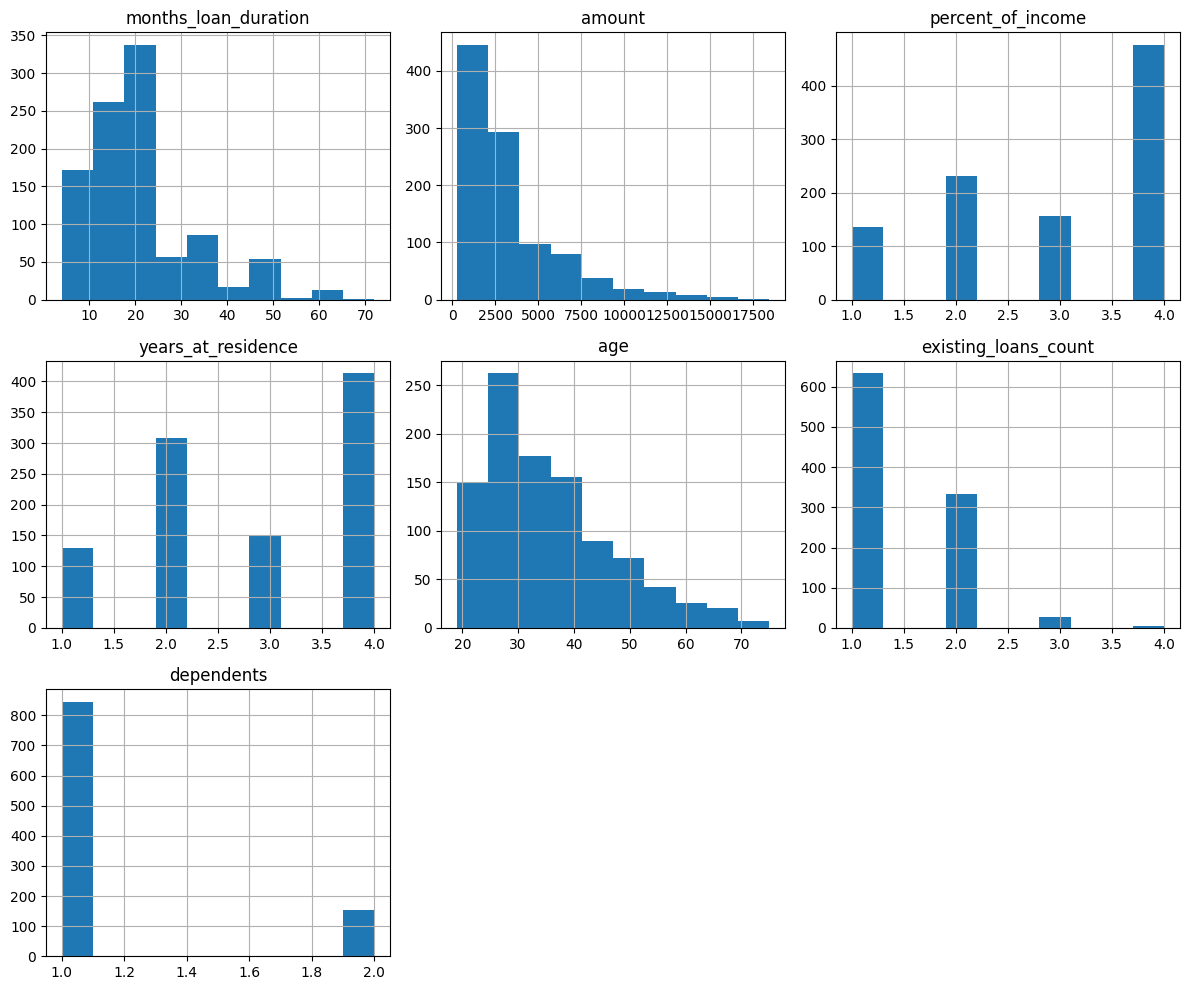

In [22]:
# Distribución de algunas numéricas
num_cols = df.select_dtypes(include=["int64", "float64"]).columns
df[num_cols].hist(figsize=(12, 10))
plt.tight_layout()

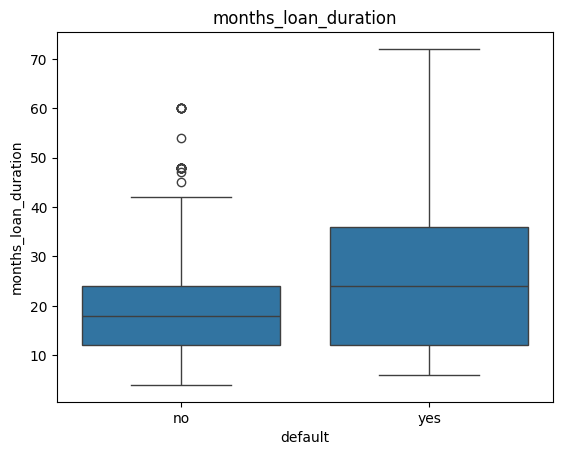

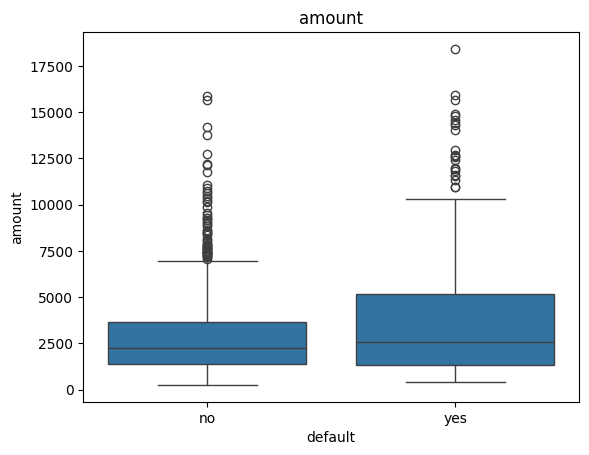

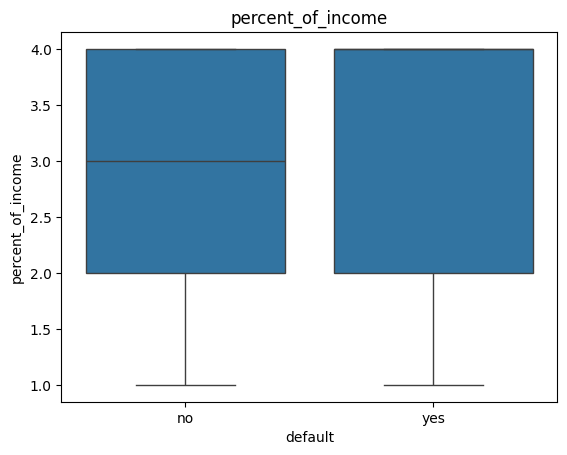

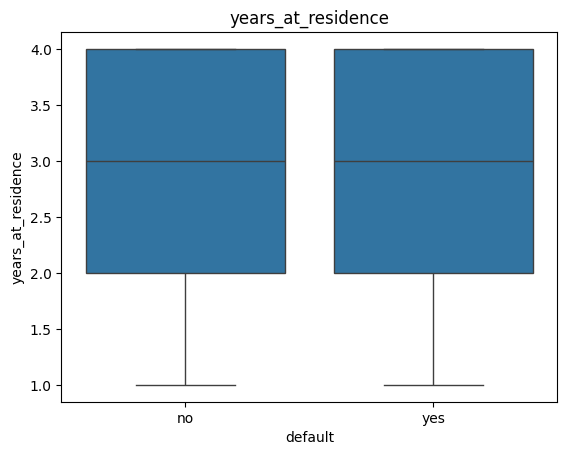

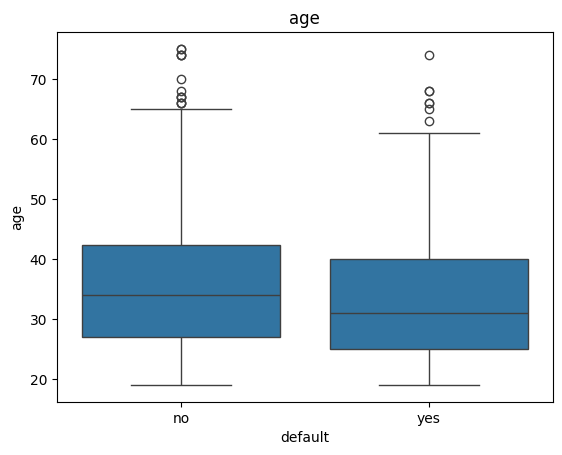

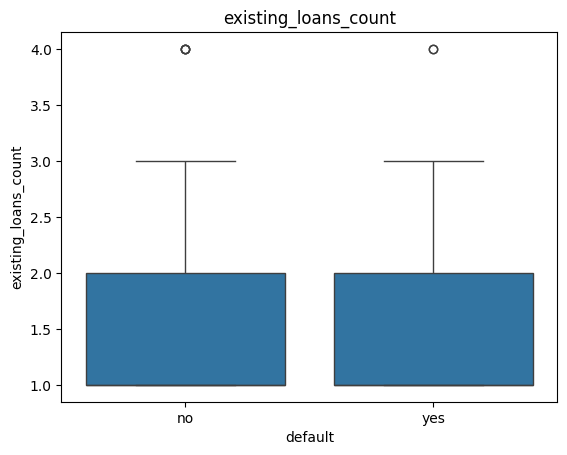

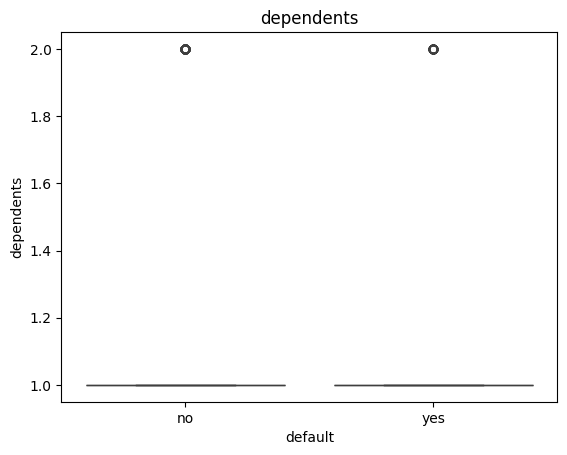

In [23]:
# Boxplots por target
for col in num_cols:
    sns.boxplot(x=df[target_col], y=df[col])
    plt.title(col)
    plt.show()

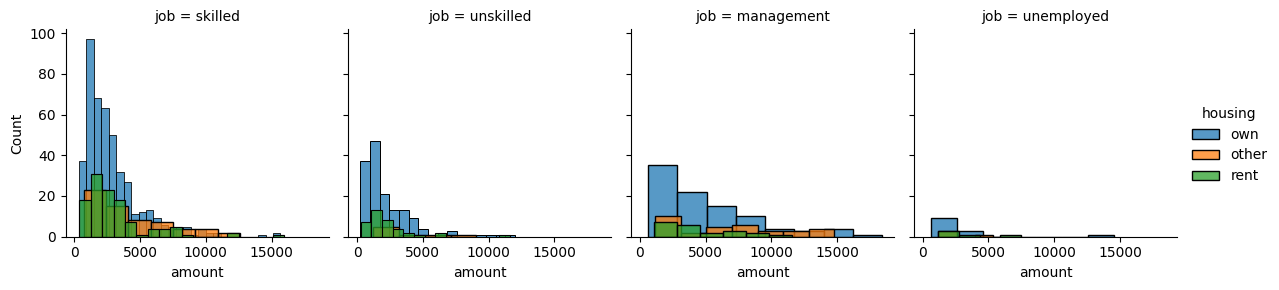

In [24]:
g = sns.FacetGrid(df,col='job',hue ='housing',col_wrap=4)
g.map(sns.histplot,'amount')
g.add_legend()
plt.show()

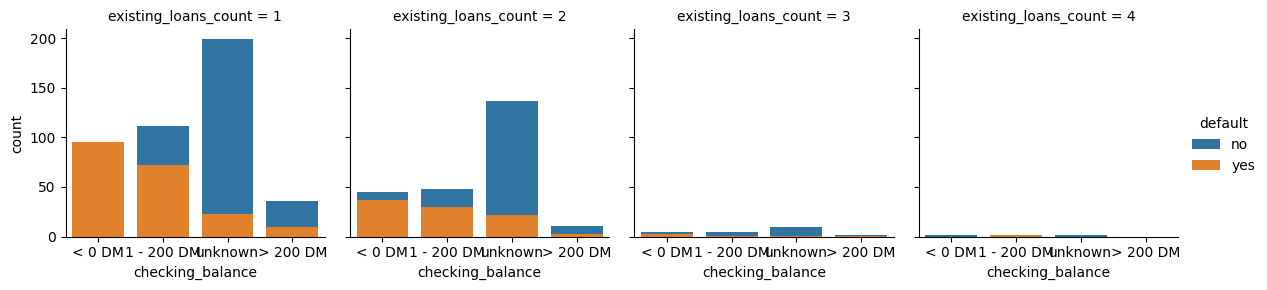

In [25]:
g = sns.FacetGrid(df, col='existing_loans_count', hue='default', col_wrap=4)
g.map(sns.countplot, 'checking_balance', order=df['checking_balance'].unique())  
g.add_legend()
plt.show()

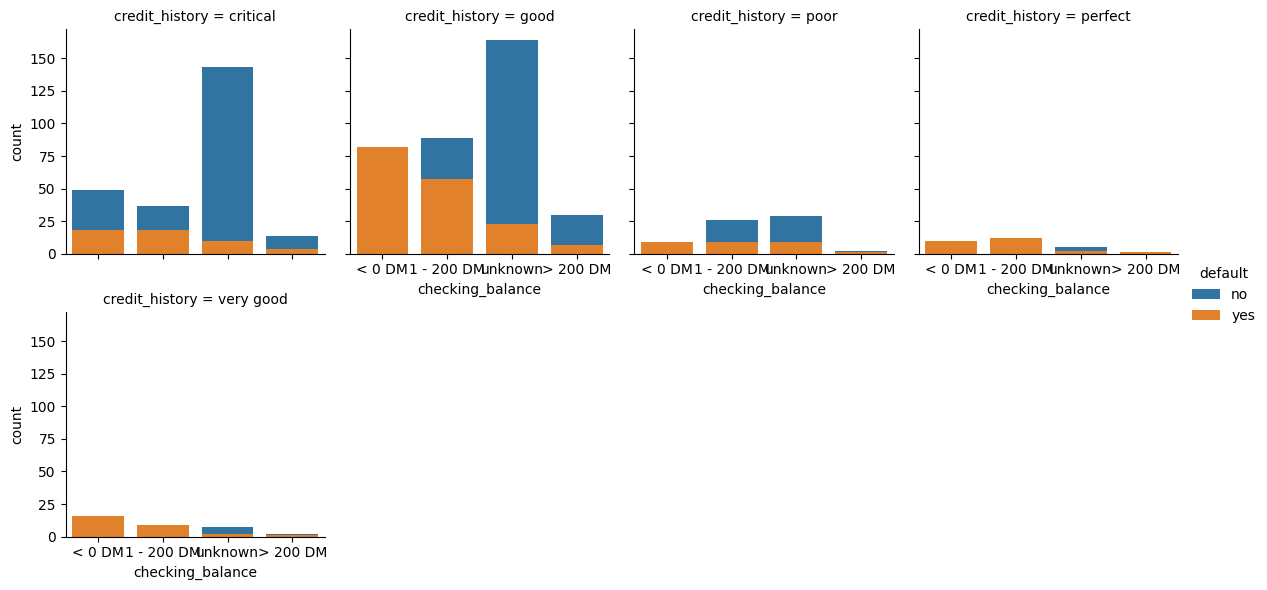

In [26]:
g = sns.FacetGrid(df, col='credit_history', hue='default', col_wrap=4)
g.map(sns.countplot, 'checking_balance', order=df['checking_balance'].unique())  
g.add_legend()
plt.show()

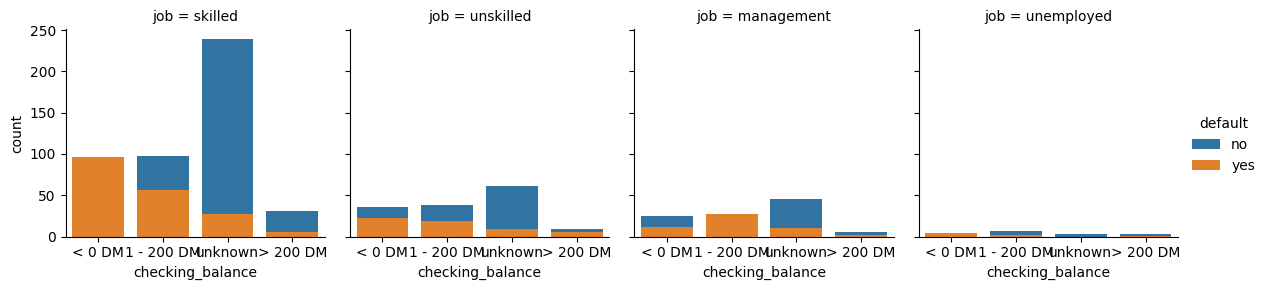

In [27]:
g = sns.FacetGrid(df, col= 'job', hue='default', col_wrap=4)
g.map(sns.countplot, 'checking_balance', order=df['checking_balance'].unique())  
g.add_legend()
plt.show()

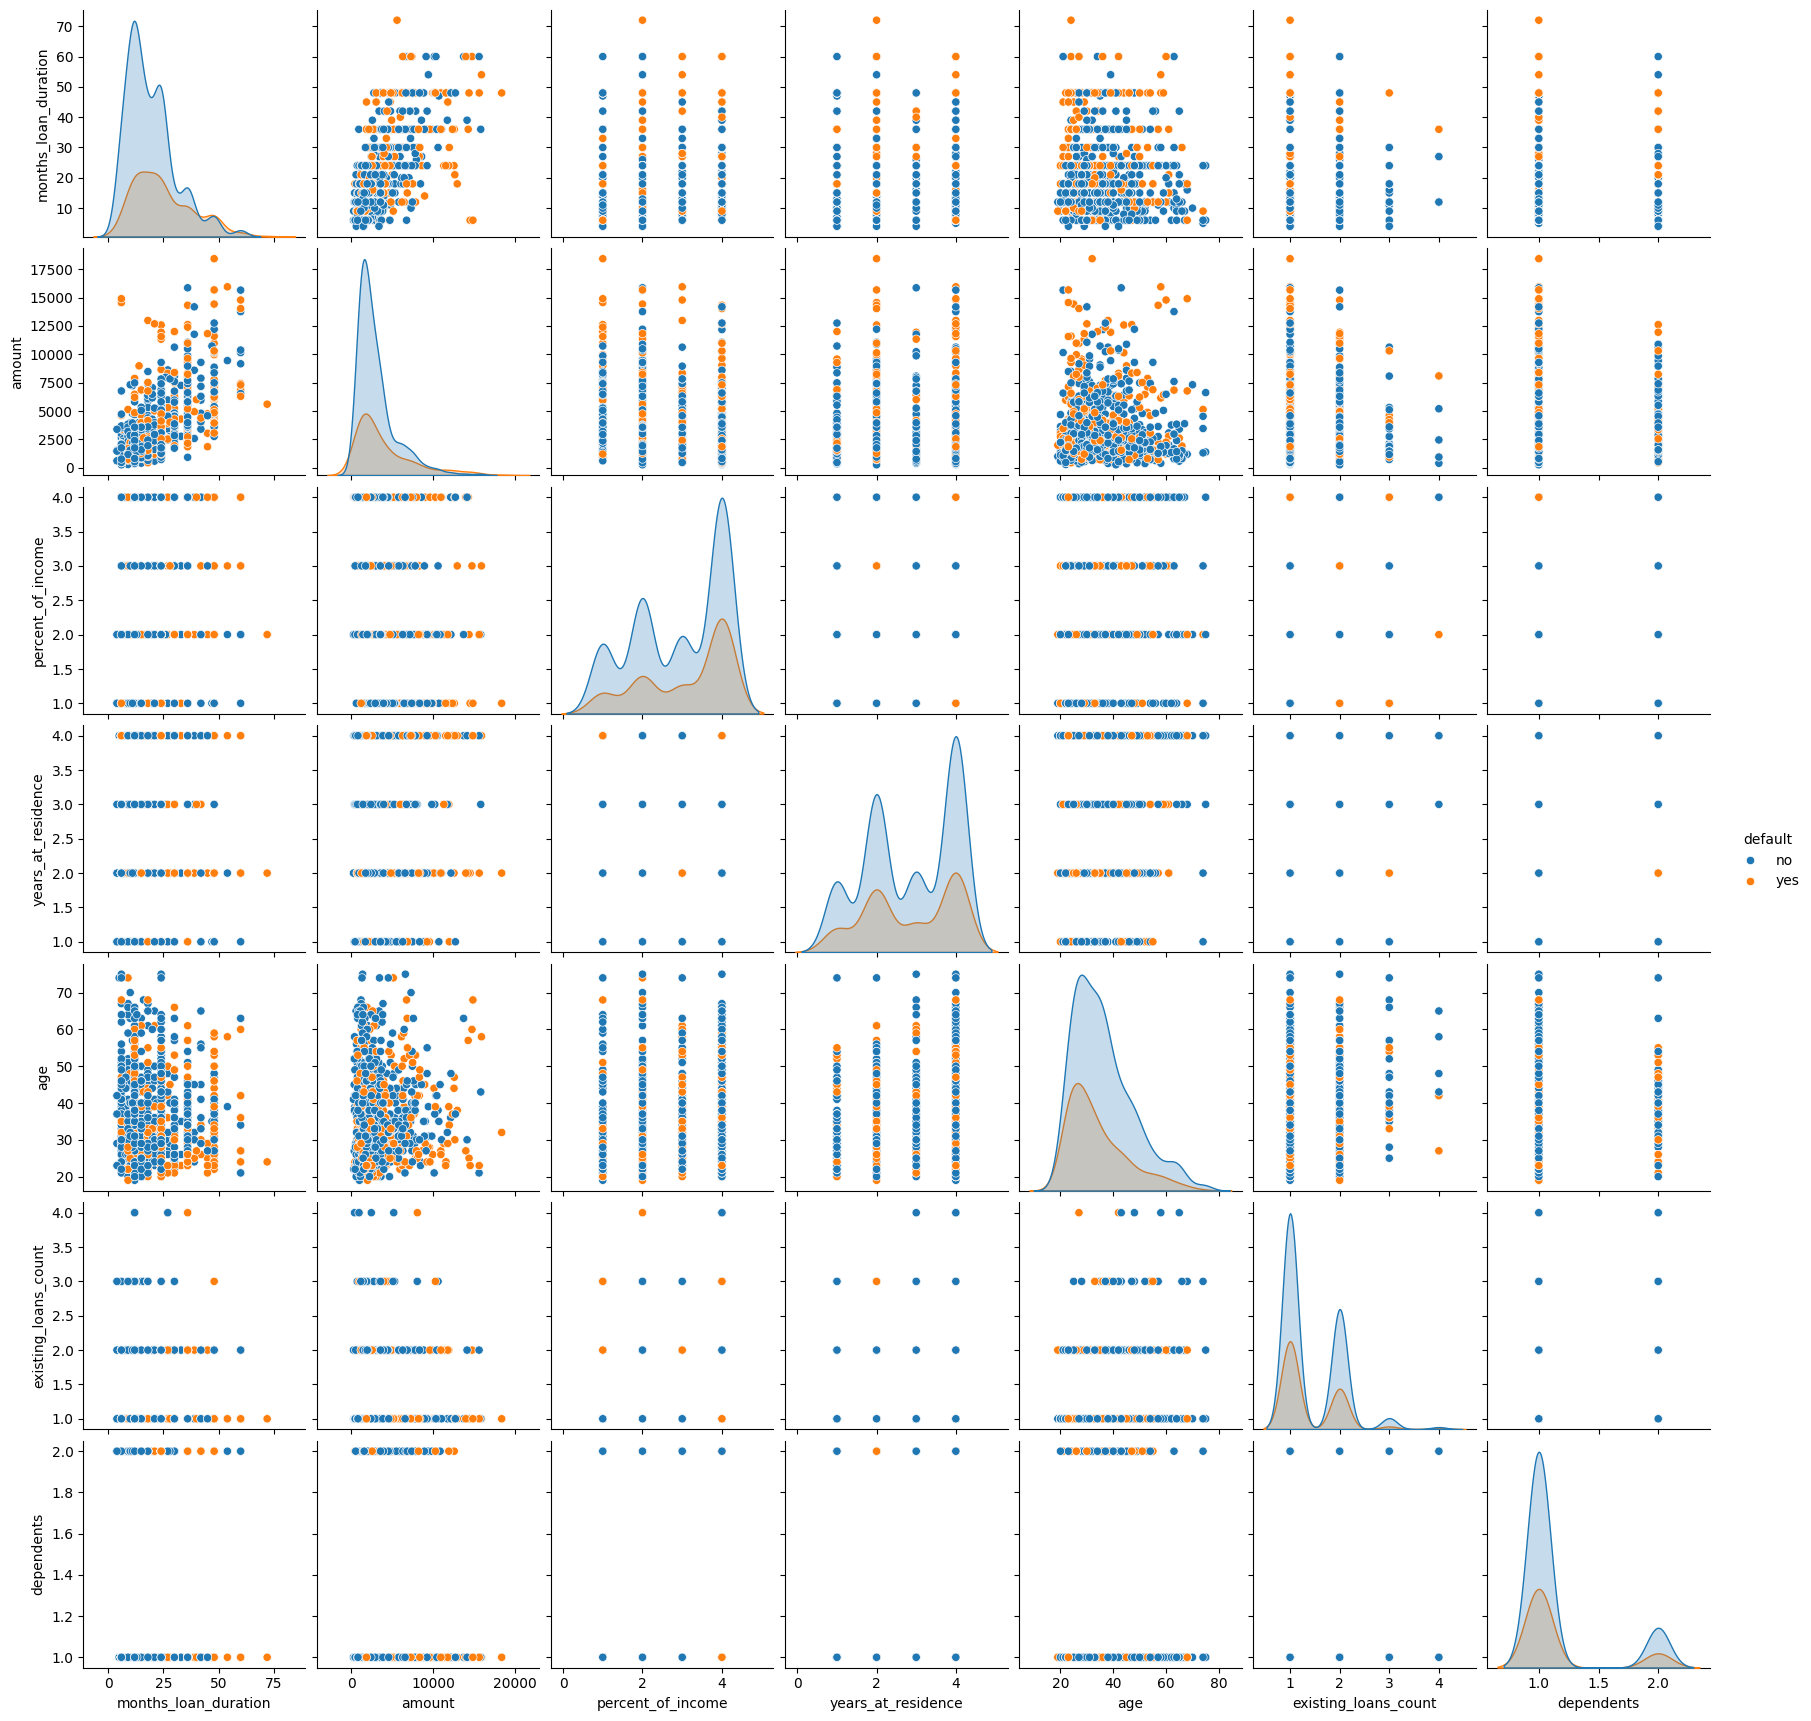

In [28]:
sns.pairplot(df, hue='default', diag_kind='kde')
plt.show()

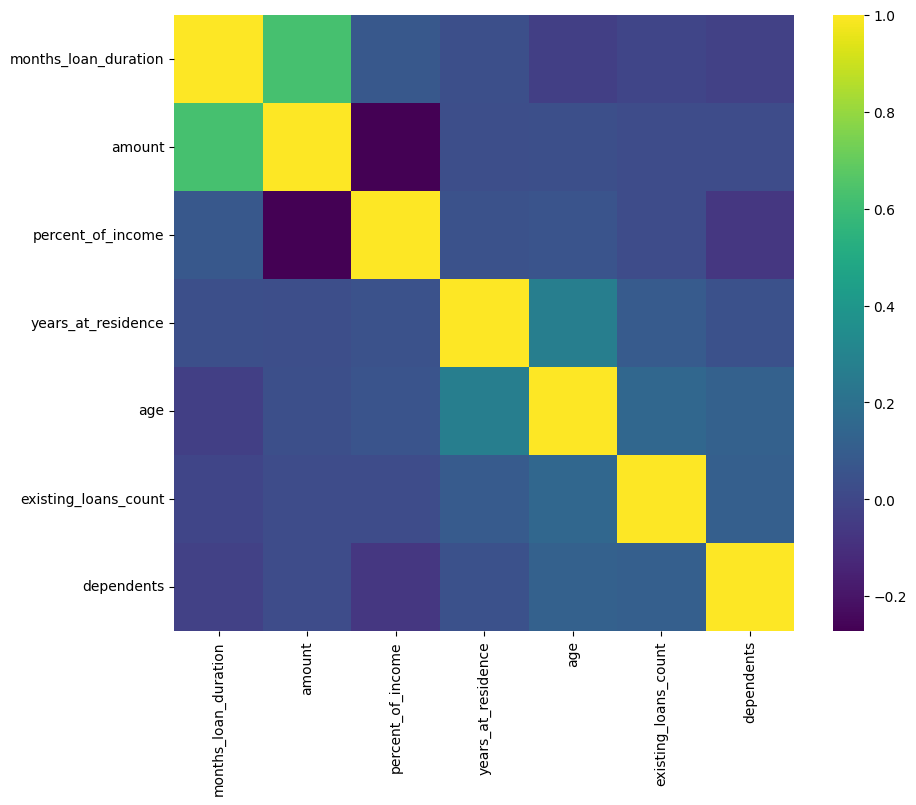

In [29]:
# Correlaciones
corr = df[num_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="viridis")
plt.show()
